# 2. The detector: model inputs, architecture, training and results

**Thesis:** *Detection of Persistent Memory Poisoning in LLM Agents Using Temporal Graph Neural
Networks* (KNUST MSc).
**Benchmark:** `data/raw/ap_burst2k_nodup`, built in `01_benchmark.ipynb`.
**Configuration:** the one behind `experiments/audit/RESULTS_FREEZE_2.md`. Each sequence is read
as one window of 20 snapshots; arrival edges join records that arrived up to 10 interactions
apart; ten arrival-coherence columns are added to every record.

This notebook holds the code of the method, cell by cell: how a snapshot becomes model input,
the temporal detector and the static graph model (and the ablations), the training loop and the
evaluation. It can retrain any configuration of the thesis from scratch. Section 7 checks, with
the repository's own code, that the code here is the code that produced the reported results.

| Section | What it does | Time on a Quadro P2000 |
|---|---|---|
| 1 | Settings | seconds |
| 2 | Model inputs: snapshots, structural features, arrival edges, coherence features | about 1 min (10 min if the cache must be built) |
| 3 | The models | seconds |
| 4 | The training and scoring code | seconds |
| 5 | Training: a short demonstration, or full training from scratch | 3 min (demonstration); 2.5 to 6 h per model (full) |
| 6 | Results: scores the models of one seed, then the five-seed headline | about 10 min |
| 7 | Check against the repository's code | about 5 min |

**To retrain**, set `TRAIN_MODELS` below (for example `["tgn", "static_attn"]` for the combined
detector of one seed) and run all cells. Keep the notebook open while it trains. A model that
has finished is not trained again; delete its folder under `experiments/notebook_runs/` to
repeat it. Training on a GPU is not bit-reproducible, so a retrained model's scores differ
slightly from the reported model of the same seed; section 6 compares it with the spread of
the five reported seeds.

## 1. Settings

In [1]:
SEED = 1                 # training seed; the thesis reports seeds 1 to 5
TRAIN_MODELS = []        # configurations to train from scratch, e.g. ["tgn", "static_attn"];
                         # the names are listed in MODELS below
QUICK_DEMO = True        # train the detector for 3 epochs on 100 sequences (about 3 min)
RUN_CHECKS = True        # section 7: compare this notebook's code with the repository's

In [2]:
import copy
import json
import os
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from torch.utils.data import DataLoader, Dataset
from torch_geometric.data import Batch, Data
from torch_geometric.nn import GATConv, global_mean_pool
from torch_geometric.utils import softmax as scatter_softmax

here = Path.cwd().resolve()
ROOT = here if (here / "src").exists() else here.parent
os.chdir(ROOT)
DATA = ROOT / "data" / "raw" / "ap_burst2k_nodup"          # the benchmark
REPORTED = ROOT / "experiments" / "seeds_coherence"         # the 40 models of freeze 2
RUNS = ROOT / "experiments" / "notebook_runs"               # models trained by this notebook
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Repository ", ROOT)
print("Python     ", sys.version.split()[0], "| torch", torch.__version__)
print("Device     ", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

Repository  E:\BackUp\PRJTS\msearch\impl\AI-poisoned
Python      3.12.10 | torch 2.5.1+cu121
Device      cuda (Quadro P2000)


The configuration. These are the values of `configs/default.yaml` with the overrides the freeze
runs were given on the command line (`src/experiments/coherence_plan.py`, `CONFIG`); section 7.1
compares them with the `run_config.json` every reported run wrote.

In [3]:
CONFIG = {
    "simulation": {"embedding_dim": 384},      # all-MiniLM-L6-v2 sentence embedding
    "model": {
        "node_feature_dim": 384,               # embedding columns; the other columns are added below
        "node_memory_dim": 128,                # per-node GRU memory
        "gat_hidden_dim": 128,                 # graph attention: 2 layers, 4 heads then 1
        "gat_heads": 4,
        "gru_hidden_dim": 128,                 # temporal aggregator
        "mlp_hidden_dim": 64,                  # scoring heads and attention pooling
        "dropout": 0.3,
        "readout": "attention",                # attention pooling over nodes
        "memory_slots": "per_window",          # each window in a batch has its own memory
    },
    "training": {
        "temporal_window": 20,                 # snapshots per window: the whole sequence
        "batch_size": 4,                       # sized for a 4 GB GPU
        "learning_rate": 1e-4,                 # Adam
        "weight_decay": 1e-5,
        "epochs_supervised": 66,               # with early stopping (patience 10)
        "early_stopping_patience": 10,         # on validation AUROC
        "gradient_clip": 1.0,
        "focal_loss_gamma": 3.0,               # node-level focal loss
        "focal_loss_alpha": 0.85,
        "loss_alpha": 1.0,                     # weight on the sequence-level loss
        "loss_beta": 1.5,                      # weight on the node-level loss
    },
}
ARRIVAL_WINDOW = 10                            # arrival edges: records at most 10 interactions apart
NOISE = {"prob": 0.5, "sigma_max": 0.15}       # embedding-noise augmentation during training
EMB_DIM = CONFIG["simulation"]["embedding_dim"]

# Every configuration of the freeze. All share the recipe above.
MODELS = {
    "tgn":             "Temporal detector (node memory, graph attention, attention pooling, GRU)",
    "static_attn":     "Static GAT: the final snapshot only, attention pooling",
    "no_memory":       "Detector without the per-node memory",
    "no_aggregator":   "Detector without the temporal aggregator",
    "static_wide":     "Static GAT widened to the detector's parameter count",
    "meanpool":        "Detector with mean pooling in place of attention pooling",
    "nostruct":        "Detector without the four structural columns",
    "tgn_nocoherence": "Detector without the ten coherence columns",
}


def inputs_for(kind):
    """What the dataset gives a configuration: which columns, which edges, how many snapshots."""
    return {"temporal_window": CONFIG["training"]["temporal_window"],
            "arrival_window": ARRIVAL_WINDOW,
            "structural": kind != "nostruct",
            "coherence": kind != "tgn_nocoherence"}


splits = json.load(open(DATA / "splits.json"))
meta = {m["sequence_id"]: m for m in json.load(open(DATA / "metadata.json"))}
print({k: len(v) for k, v in splits.items()}, "sequences per partition")

{'train': 1200, 'val': 300, 'test': 500} sequences per partition


## 2. Model inputs

### 2.1 A snapshot as stored

Each snapshot is one compressed file. A record is a node with 387 columns: its 384 embedding
columns, then recency, retrieval frequency and retrieval recency. Edges join records whose cosine
similarity exceeds 0.6, in both directions, weighted by that similarity. `node_labels` marks the
records the attacker placed; `graph_label` is 1 once the snapshot holds one.

In [4]:
EXAMPLE = "poisoned_placement_0001"
z = np.load(DATA / EXAMPLE / "snapshot_0019.npz")
for k in z.files:
    print(f"{k:<16}{str(z[k].shape):<14}{z[k].dtype}")
print(f"\n{EXAMPLE}, final snapshot: {z['node_features'].shape[0]} records, "
      f"{int(z['node_labels'].sum())} placed by the attacker, {z['edge_index'].shape[1]} directed edges")

node_features   (200, 387)    float64
edge_index      (2, 176)      int64
edge_weights    (176,)        float64
node_labels     (200,)        int64
graph_label     (1,)          int64
timestamp       (1,)          int64

poisoned_placement_0001, final snapshot: 200 records, 12 placed by the attacker, 176 directed edges


### 2.2 Structural features

Graph attention normalises its weights over each node's neighbours, so it computes a weighted
average and cannot count neighbours. Four columns hand it what its aggregation cannot derive:
degree (divided by 50, and by n - 1) and the mean and largest weight of a record's edges.
They are computed from the similarity edges.

In [5]:
STRUCTURAL = 4


def structural_features(num_nodes, edge_index, edge_weights):
    """Columns [degree / 50, degree / (n - 1), mean edge weight, max edge weight] per record."""
    out = np.zeros((num_nodes, STRUCTURAL), dtype=np.float64)
    if edge_index.size == 0 or num_nodes == 0:
        return out
    src = np.asarray(edge_index[0], dtype=np.int64)
    w = np.asarray(edge_weights, dtype=np.float64).reshape(-1)
    if w.size != src.size:
        w = np.ones_like(src, dtype=np.float64)
    deg = np.zeros(num_nodes); np.add.at(deg, src, 1.0)
    wsum = np.zeros(num_nodes); np.add.at(wsum, src, w)
    wmax = np.zeros(num_nodes); np.maximum.at(wmax, src, w)
    with np.errstate(invalid="ignore", divide="ignore"):
        wmean = np.where(deg > 0, wsum / np.maximum(deg, 1.0), 0.0)
    out[:, 0], out[:, 1] = deg / 50.0, deg / max(num_nodes - 1, 1)
    out[:, 2], out[:, 3] = wmean, wmax
    return out


s = structural_features(len(z["node_labels"]), z["edge_index"], z["edge_weights"])
inj = z["node_labels"] == 1
print(f"Mean degree: injected records {50 * s[inj, 0].mean():.1f}, others {50 * s[~inj, 0].mean():.1f}")

Mean degree: injected records 0.6, others 0.9


### 2.3 Arrival edges

Only a quarter of the pairs inside an attack burst clear the 0.6 similarity threshold, so the
similarity graph shows most of a burst as unconnected. Arrival edges join every two records that
arrived at most 10 interactions apart, whatever their similarity, weighted by their cosine.
Every edge then carries two attributes: [weight, 1 if it is an arrival edge].

In [6]:
def with_arrival_edges(data, window, emb_dim=EMB_DIM):
    n = data.x.size(0)
    sim_attr = torch.cat([data.edge_attr, torch.zeros((data.edge_attr.size(0), 1))], dim=1)
    if n < 2:
        data.edge_attr = sim_attr
        return data
    u = F.normalize(data.x[:, :emb_dim].float(), dim=1)
    src, dst = [], []
    for d in range(1, min(window, n - 1) + 1):        # record i arrived at interaction i
        i = torch.arange(n - d)
        src += [i, i + d]
        dst += [i + d, i]
    src, dst = torch.cat(src), torch.cat(dst)
    cos = (u[src] * u[dst]).sum(dim=1, keepdim=True)
    data.edge_index = torch.cat([data.edge_index, torch.stack([src, dst])], dim=1)
    data.edge_attr = torch.cat([sim_attr, torch.cat([cos, torch.ones_like(cos)], dim=1)])
    return data

### 2.4 Arrival-coherence features

An attack is a run of consecutive records that are unusually alike. Ten columns per record
measure how alike a record is to the records that arrived around it, from the embeddings and the
arrival order only:

* for each block length L in 5, 10, 15 and 20: the highest mean pairwise cosine over the runs of
  L consecutive records containing the record, and the same minus its median over the snapshot
  (ordinary sessions are alike too);
* for k in 5 and 10: the mean cosine to the records that arrived at most k interactions before
  or after it.

These are specific to this attack, which the thesis states.

In [7]:
COHERENCE_BLOCKS = (5, 10, 15, 20)
COHERENCE_NEIGHBOURS = (5, 10)
COHERENCE_DIM = 2 * len(COHERENCE_BLOCKS) + len(COHERENCE_NEIGHBOURS)


def coherence_columns(x, emb_dim=EMB_DIM):
    n = x.size(0)
    cols = torch.zeros((n, COHERENCE_DIM))
    if n < 2:
        return cols
    u = F.normalize(x[:, :emb_dim].float(), dim=1)
    S = u @ u.T
    S.fill_diagonal_(0.0)
    P = F.pad(S.cumsum(0).cumsum(1), (1, 0, 1, 0))     # 2-D prefix sums: any block sum in O(1)
    idx = torch.arange(n)
    c = 0
    for L in COHERENCE_BLOCKS:
        L = min(L, n)
        s = torch.arange(n - L + 1)                     # block starts
        block = (P[s + L, s + L] - P[s, s + L] - P[s + L, s] + P[s, s]) / (L * (L - 1))
        inside = (s[None, :] <= idx[:, None]) & (idx[:, None] <= s[None, :] + L - 1)
        best = block[None, :].expand(n, -1).masked_fill(~inside, -2.0).max(dim=1).values
        cols[:, c], cols[:, c + 1] = best, best - best.median()
        c += 2
    dist = (idx[:, None] - idx[None, :]).abs()
    for k in COHERENCE_NEIGHBOURS:
        band = ((dist >= 1) & (dist <= k)).float()
        cols[:, c] = (S * band).sum(1) / band.sum(1).clamp(min=1.0)
        c += 1
    return cols

One column (blocks of 10, relative to the snapshot median) at the final snapshot of every test
sequence: the records the attacker placed against all other records. In a single sequence an
ordinary topical session can score as high as the attack, since sessions are alike too; across
the partition the placed records stand out.

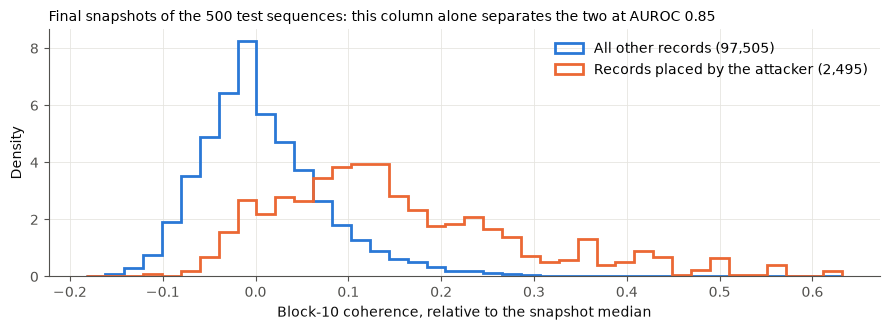

In [8]:
BLUE, ORANGE, AQUA, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#a9a8a2", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.6, "font.size": 10})

placed, other = [], []
for sid in sorted(splits["test"]):
    zz = np.load(DATA / sid / "snapshot_0019.npz")
    col = coherence_columns(torch.tensor(zz["node_features"], dtype=torch.float32))[:, 3].numpy()
    lab = zz["node_labels"] == 1
    placed.append(col[lab]); other.append(col[~lab])
placed, other = np.concatenate(placed), np.concatenate(other)
sep = roc_auc_score(np.r_[np.ones(len(placed)), np.zeros(len(other))], np.r_[placed, other])

fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(min(placed.min(), other.min()), max(placed.max(), other.max()), 41)
ax.hist(other, bins=bins, density=True, histtype="step", linewidth=2, color=BLUE,
        label=f"All other records ({len(other):,})")
ax.hist(placed, bins=bins, density=True, histtype="step", linewidth=2, color=ORANGE,
        label=f"Records placed by the attacker ({len(placed):,})")
ax.set_xlabel("Block-10 coherence, relative to the snapshot median"); ax.set_ylabel("Density")
ax.set_title(f"Final snapshots of the 500 test sequences: this column alone separates the two "
             f"at AUROC {sep:.2f}", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 2.5 Reading the snapshots fast: the per-sequence cache

The snapshots of a sequence are nested (snapshot t holds records 0 to 10(t + 1) - 1, and a
record's embedding never changes), so all 20 are stored once per sequence: the final embeddings,
the other columns of every snapshot (with the four structural columns already computed), and
the edges exactly as stored. That is about 0.4 MB per sequence instead of twenty compressed
files, and it returns exactly the same tensors (section 7.2 checks this). It is built from the
corpus on first use.

In [9]:
CACHE = DATA / "_seqcache" / "struct"


def build_cache_sequence(seq_dir, emb_dim=EMB_DIM):
    side, eidx, ew, eoff, n_nodes, glabel, embs = [], [], [], [0], [], [], []
    emb = labels = None
    for p in sorted(seq_dir.glob("snapshot_*.npz")):
        with np.load(p) as zz:
            f, ei, w = zz["node_features"], zz["edge_index"], zz["edge_weights"]
            nl, gl = zz["node_labels"], zz["graph_label"]
        f = np.concatenate([f, structural_features(f.shape[0], ei, w)], axis=1)
        n = f.shape[0]
        embs.append(f[:, :emb_dim].astype(np.float32))
        if emb is None or n > emb.shape[0]:
            emb, labels = embs[-1], np.asarray(nl).astype(np.int64)
        side.append(f[:, emb_dim:].astype(np.float32))
        eidx.append(np.asarray(ei, dtype=np.int64).reshape(2, -1))
        ew.append(np.asarray(w, dtype=np.float32).reshape(-1))
        eoff.append(eoff[-1] + eidx[-1].shape[1])
        n_nodes.append(n)
        glabel.append(int(np.asarray(gl).reshape(-1)[0]))
    for e in embs:
        assert np.array_equal(e, emb[:e.shape[0]]), f"{seq_dir.name}: embeddings not nested"
    return {"emb": emb, "labels": labels, "side": np.concatenate(side, axis=0),
            "side_off": np.cumsum([0] + n_nodes), "edge_index": np.concatenate(eidx, axis=1),
            "edge_weight": np.concatenate(ew), "edge_off": np.array(eoff),
            "n_nodes": np.array(n_nodes), "graph_label": np.array(glabel)}


CACHE.mkdir(parents=True, exist_ok=True)
missing = [sid for sid in meta if not (CACHE / f"{sid}.npz").exists()]
for i, sid in enumerate(missing):
    np.savez(CACHE / f"{sid}.npz", **build_cache_sequence(DATA / sid))
    if i % 200 == 0:
        print(f"  building the cache: {i} of {len(missing)}", flush=True)
print(f"Cache: {len(meta) - len(missing)} sequences present, {len(missing)} built now")

Cache: 2000 sequences present, 0 built now


### 2.6 The dataset

One item is a window of T consecutive snapshots of one sequence, as PyTorch Geometric graphs,
with the label of its last snapshot. With T = 20 there is one window per sequence, so the window
score is the sequence score. `node_ids` gives each record the same identity in every snapshot,
which is how the node memory follows a record over time.

In [10]:
class SequenceStore:
    """Cached sequences, loaded on demand; the most recent 64 are kept in memory."""

    def __init__(self, keep=64):
        self.keep, self.mem = keep, {}

    def get(self, sid):
        if sid not in self.mem:
            if len(self.mem) >= self.keep:
                self.mem.pop(next(iter(self.mem)))
            with np.load(CACHE / f"{sid}.npz") as zz:
                self.mem[sid] = {k: zz[k] for k in zz.files}
        return self.mem[sid]

    def snapshot(self, sid, t, structural=True):
        s = self.get(sid)
        n = int(s["n_nodes"][t])
        side = s["side"][s["side_off"][t]:s["side_off"][t + 1], :None if structural else 3]
        e0, e1 = s["edge_off"][t], s["edge_off"][t + 1]
        w = torch.from_numpy(s["edge_weight"][e0:e1].copy())
        return Data(x=torch.from_numpy(np.concatenate([s["emb"][:n], side], axis=1)),
                    edge_index=torch.from_numpy(s["edge_index"][:, e0:e1].copy()),
                    edge_attr=w.unsqueeze(-1) if w.numel() > 0 else torch.zeros((0, 1)),
                    y=torch.tensor(int(s["graph_label"][t])),
                    node_labels=torch.from_numpy(s["labels"][:n].copy()),
                    node_ids=torch.arange(n, dtype=torch.long))


class TrajectoryDataset(Dataset):
    def __init__(self, sequence_ids, temporal_window=20, arrival_window=10, structural=True,
                 coherence=True):
        self.T, self.arrival_window = temporal_window, arrival_window
        self.structural, self.coherence = structural, coherence
        self.store = SequenceStore()
        self._coherence = {}      # (sequence, snapshot) -> columns, computed once
        self.windows = [(sid, start) for sid in sequence_ids
                        for start in range(max(1, meta[sid]["num_snapshots"] - temporal_window + 1))]

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, i):
        sid, start = self.windows[i]
        graphs = [self.store.snapshot(sid, t, self.structural) for t in range(start, start + self.T)]
        if self.arrival_window > 0:
            graphs = [with_arrival_edges(g, self.arrival_window) for g in graphs]
        if self.coherence:
            for t, g in enumerate(graphs, start=start):
                if (sid, t) not in self._coherence:
                    self._coherence[(sid, t)] = coherence_columns(g.x)
                g.x = torch.cat([g.x, self._coherence[(sid, t)]], dim=1)
        return {"graphs": graphs, "label": graphs[-1].y.item(), "sequence_id": sid, "start": start}


def collate(items):
    """A batch: for each of the T snapshots, the windows' graphs joined into one Batch."""
    T = len(items[0]["graphs"])
    return {"graphs": [Batch.from_data_list([it["graphs"][t] for it in items]) for t in range(T)],
            "labels": torch.tensor([it["label"] for it in items], dtype=torch.float32),
            "sequence_ids": [it["sequence_id"] for it in items]}


item = TrajectoryDataset([EXAMPLE])[0]
g = item["graphs"][-1]
print(f"{EXAMPLE}: {len(item['graphs'])} snapshots, label {item['label']}")
print(f"final snapshot: x {tuple(g.x.shape)} = 384 embedding + 3 metadata + {STRUCTURAL} structural "
      f"+ {COHERENCE_DIM} coherence; edge_attr {tuple(g.edge_attr.shape)}")

poisoned_placement_0001: 20 snapshots, label 1
final snapshot: x (200, 401) = 384 embedding + 3 metadata + 4 structural + 10 coherence; edge_attr (4066, 2)


## 3. The models

### 3.1 Building blocks

In [11]:
class NodeMemoryModule(nn.Module):
    """A GRU cell that carries one memory vector per record from snapshot to snapshot."""

    def __init__(self, input_dim, memory_dim):
        super().__init__()
        self.memory_dim = memory_dim
        self.gru_cell = nn.GRUCell(input_dim, memory_dim)

    def forward(self, x, prev_memory):
        return self.gru_cell(x, prev_memory)


class GraphEncoder(nn.Module):
    """Two graph attention layers (4 heads, then 1) over the snapshot's edges."""

    def __init__(self, input_dim, hidden_dim, num_heads=4, dropout=0.3, edge_dim=1):
        super().__init__()
        self.gat1 = GATConv(input_dim, hidden_dim, heads=num_heads, dropout=dropout, concat=True,
                            edge_dim=edge_dim)
        self.gat2 = GATConv(hidden_dim * num_heads, hidden_dim, heads=1, dropout=dropout,
                            concat=False, edge_dim=edge_dim)
        self.dropout = dropout

    def forward(self, x, edge_index, edge_attr=None):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.gat1(x, edge_index, edge_attr=edge_attr))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.gat2(x, edge_index, edge_attr=edge_attr)


class AttentionPool(nn.Module):
    """Learned attention over the records of a graph (multiple-instance style), so a small
    anomalous cluster is not averaged away among hundreds of ordinary records."""

    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.attn = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.Tanh(),
                                  nn.Linear(hidden_dim, 1))

    def forward(self, x, batch_idx, num_graphs=None):
        weights = scatter_softmax(self.attn(x).squeeze(-1), batch_idx)
        if num_graphs is None:
            num_graphs = int(batch_idx.max().item()) + 1 if batch_idx.numel() > 0 else 0
        return x.new_zeros(num_graphs, x.size(-1)).index_add(0, batch_idx, x * weights.unsqueeze(-1))


class TemporalAggregator(nn.Module):
    """A GRU over the sequence of pooled snapshot embeddings; returns its last hidden state."""

    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, batch_first=True)

    def forward(self, seq):
        _, h_n = self.gru(seq)
        return h_n.squeeze(0)


class GraphAnomalyHead(nn.Module):
    """The sequence score: probability that the memory is being poisoned."""

    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(hidden_dim, 1))

    def forward(self, h):
        return torch.sigmoid(self.mlp(h)).squeeze(-1)


class NodeAnomalyHead(nn.Module):
    """A score per record of the last snapshot: probability that the attacker placed it."""

    def __init__(self, node_dim, context_dim, hidden_dim):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(node_dim + context_dim, hidden_dim), nn.ReLU(),
                                 nn.Dropout(0.3), nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
                                 nn.Dropout(0.2), nn.Linear(hidden_dim, 1))

    def forward(self, node_embeddings, context, batch_idx):
        combined = torch.cat([node_embeddings, context[batch_idx]], dim=-1)
        return torch.sigmoid(self.mlp(combined)).squeeze(-1)

### 3.2 The temporal detector

At every snapshot: each record's memory is updated from its features and its previous memory;
graph attention reads the features and memory together over the snapshot's edges; attention
pooling turns the snapshot into one vector. A GRU then reads the 20 snapshot vectors, and two
heads score the sequence and each record of the last snapshot.

The memory is a table with one row per record. When several windows share a batch, each window
gets its own block of rows (`memory_slots: per_window`), so no state passes between windows.
Memory is stored detached, so gradients do not flow back through earlier snapshots' memory.

In [12]:
class TGNDetector(nn.Module):
    def __init__(self, config):
        super().__init__()
        m = config["model"]
        input_dim = m["node_feature_dim"] + m["node_meta_dim"]
        self.node_memory = NodeMemoryModule(input_dim, m["node_memory_dim"])
        self.graph_encoder = GraphEncoder(input_dim + m["node_memory_dim"], m["gat_hidden_dim"],
                                          m["gat_heads"], m["dropout"], m["edge_dim"])
        self.attn_pool = AttentionPool(m["gat_hidden_dim"], m["mlp_hidden_dim"])
        self.temporal_aggregator = TemporalAggregator(m["gat_hidden_dim"], m["gru_hidden_dim"])
        self.graph_head = GraphAnomalyHead(m["gru_hidden_dim"], m["mlp_hidden_dim"])
        self.node_head = NodeAnomalyHead(m["gat_hidden_dim"], m["gru_hidden_dim"], m["mlp_hidden_dim"])
        self.gat_hidden, self.memory_dim = m["gat_hidden_dim"], m["node_memory_dim"]

    def pool(self, h, g):
        return self.attn_pool(h, g.batch, num_graphs=g.num_graphs)

    def run_memory(self, graph_sequence):
        """Update every record's memory snapshot by snapshot; yields (snapshot, its memories)."""
        stride = max(int(g.node_ids.max()) for g in graph_sequence) + 1     # rows per window
        g0 = graph_sequence[0]
        bank = torch.zeros(g0.num_graphs * stride, self.memory_dim, device=g0.x.device)
        for g in graph_sequence:
            rows = g.node_ids + g.batch * stride       # this window's block of the table
            mem = self.node_memory(g.x, bank[rows])
            bank[rows] = mem.detach()
            yield g, mem

    def forward(self, graph_sequence):
        pooled = []
        for g, mem in self.run_memory(graph_sequence):
            h = self.graph_encoder(torch.cat([g.x, mem], dim=-1), g.edge_index, g.edge_attr)
            pooled.append(self.pool(h, g))
        trajectory = self.temporal_aggregator(torch.stack(pooled, dim=1))
        return self.graph_head(trajectory), self.node_head(h, trajectory, g.batch)

### 3.3 The static graph model

The detector with both temporal components removed: it reads the final snapshot only, with the
same graph attention, pooling and heads, trained by the same loop.

In [13]:
class StaticGAT(nn.Module):
    def __init__(self, config):
        super().__init__()
        m = config["model"]
        input_dim = m["node_feature_dim"] + m["node_meta_dim"]
        self.graph_encoder = GraphEncoder(input_dim, m["gat_hidden_dim"], m["gat_heads"],
                                          m["dropout"], m["edge_dim"])
        self.attn_pool = AttentionPool(m["gat_hidden_dim"], m["mlp_hidden_dim"])
        self.graph_head = GraphAnomalyHead(m["gat_hidden_dim"], m["mlp_hidden_dim"])
        self.node_head = NodeAnomalyHead(m["gat_hidden_dim"], m["gat_hidden_dim"], m["mlp_hidden_dim"])

    def forward(self, graph_sequence):
        g = graph_sequence[-1]                   # the earlier snapshots are not read
        h = self.graph_encoder(g.x, g.edge_index, g.edge_attr)
        pooled = self.attn_pool(h, g.batch, num_graphs=g.num_graphs)
        return self.graph_head(pooled), self.node_head(h, pooled, g.batch)

### 3.4 The ablations

Each removes or replaces one component. They are built the way the repository builds them
(the full model first, then the change), so that a given seed initialises them identically.

In [14]:
class TGNNoMemory(TGNDetector):
    """Temporal aggregator kept; per-node memory removed (attention reads raw features)."""

    def __init__(self, config):
        super().__init__(config)
        m = config["model"]
        del self.node_memory
        self.graph_encoder = GraphEncoder(m["node_feature_dim"] + m["node_meta_dim"],
                                          m["gat_hidden_dim"], m["gat_heads"], m["dropout"],
                                          m["edge_dim"])

    def forward(self, graph_sequence):
        pooled = []
        for g in graph_sequence:
            h = self.graph_encoder(g.x, g.edge_index, g.edge_attr)
            pooled.append(self.pool(h, g))
        trajectory = self.temporal_aggregator(torch.stack(pooled, dim=1))
        return self.graph_head(trajectory), self.node_head(h, trajectory, g.batch)


class TGNNoAggregator(TGNDetector):
    """Per-node memory kept over all snapshots; temporal aggregator removed (the heads read the
    final snapshot's pooled vector)."""

    def __init__(self, config):
        super().__init__(config)
        m = config["model"]
        del self.temporal_aggregator
        self.graph_head = GraphAnomalyHead(m["gat_hidden_dim"], m["mlp_hidden_dim"])
        self.node_head = NodeAnomalyHead(m["gat_hidden_dim"], m["gat_hidden_dim"], m["mlp_hidden_dim"])

    def forward(self, graph_sequence):
        for g, mem in self.run_memory(graph_sequence):
            pass
        h = self.graph_encoder(torch.cat([g.x, mem], dim=-1), g.edge_index, g.edge_attr)
        pooled = self.pool(h, g)
        return self.graph_head(pooled), self.node_head(h, pooled, g.batch)


class TGNMeanPool(TGNDetector):
    """Attention pooling replaced by the mean over records."""

    def __init__(self, config):
        super().__init__(config)
        del self.attn_pool

    def pool(self, h, g):
        return global_mean_pool(h, g.batch)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def matched_static_hidden(config):
    """The static GAT's hidden width whose parameter count is closest to the detector's."""
    target, best = n_params(TGNDetector(copy.deepcopy(config))), None
    for h in range(config["model"]["gat_hidden_dim"], 512):
        c = copy.deepcopy(config)
        c["model"]["gat_hidden_dim"] = h
        n = n_params(StaticGAT(c))
        if best is None or abs(n - target) < abs(best[1] - target):
            best = (h, n)
        if n > target:
            break
    return best[0]


class StaticGATWide(StaticGAT):
    """The static GAT widened until its size matches the detector's, so a gap between them
    cannot be put down to capacity."""

    def __init__(self, config):
        m = config["model"]
        m["gat_hidden_dim"] = m.get("static_wide_hidden") or matched_static_hidden(config)
        m["static_wide_hidden"] = m["gat_hidden_dim"]
        super().__init__(config)


MODEL_CLASSES = {"tgn": TGNDetector, "static_attn": StaticGAT, "no_memory": TGNNoMemory,
                 "no_aggregator": TGNNoAggregator, "static_wide": StaticGATWide,
                 "meanpool": TGNMeanPool, "nostruct": TGNDetector, "tgn_nocoherence": TGNDetector}


def model_config(kind):
    """The configuration with the input width and edge attributes this configuration's data has."""
    inp, cfg = inputs_for(kind), copy.deepcopy(CONFIG)
    cfg["model"]["node_meta_dim"] = (3 + (STRUCTURAL if inp["structural"] else 0)
                                     + (COHERENCE_DIM if inp["coherence"] else 0))
    cfg["model"]["edge_dim"] = 2 if inp["arrival_window"] > 0 else 1
    return cfg


def build_model(kind, cfg=None):
    return MODEL_CLASSES[kind](cfg if cfg is not None else model_config(kind))

### 3.5 Model sizes, beside those the reported runs recorded

In [15]:
rows = []
for kind, what in MODELS.items():
    n = n_params(build_model(kind))
    rec = json.load(open(REPORTED / f"{kind}_s1" / "variant.json"))["parameters"]
    rows.append((kind, what, n, rec))
print(f"{'Configuration':<17}{'Parameters':>11}{'Recorded':>11}  Description")
for kind, what, n, rec in rows:
    print(f"{kind:<17}{n:>11,}{rec:>11,}  {what}")

Configuration     Parameters   Recorded  Description
tgn                  680,515    680,515  Temporal detector (node memory, graph attention, attention pooling, GRU)
static_attn          312,003    312,003  Static GAT: the final snapshot only, attention pooling
no_memory            411,075    411,075  Detector without the per-node memory
no_aggregator        581,443    581,443  Detector without the temporal aggregator
static_wide          680,943    680,943  Static GAT widened to the detector's parameter count
meanpool             672,194    672,194  Detector with mean pooling in place of attention pooling
nostruct             676,931    676,931  Detector without the four structural columns
tgn_nocoherence      671,555    671,555  Detector without the ten coherence columns


## 4. Training and scoring code

### 4.1 Losses, augmentation and seeding

The loss is binary cross-entropy on the sequence score plus 1.5 times a focal loss on the record
scores (focal, because placed records are a few per cent of all records). On half of the
training batches, Gaussian noise with a standard deviation drawn from 0 to 0.15 is added to the
embedding columns, so the model cannot rely on exact embedding coordinates.

In [16]:
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.75):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha

    def forward(self, pred, target):
        bce = F.binary_cross_entropy(pred, target.float(), reduction="none")
        pt = torch.where(target == 1, pred, 1 - pred)
        alpha_t = torch.where(target == 1, self.alpha, 1 - self.alpha)
        return (alpha_t * (1 - pt) ** self.gamma * bce).mean()


def add_embedding_noise(graphs, prob=NOISE["prob"], sigma_max=NOISE["sigma_max"]):
    if random.random() >= prob:
        return graphs
    sigma = random.uniform(0.0, sigma_max)
    if sigma <= 0.0:
        return graphs
    for g in graphs:
        g.x = g.x.clone()
        noise = torch.randn_like(g.x[:, :EMB_DIM]) * sigma
        g.x[:, :EMB_DIM] = g.x[:, :EMB_DIM] + noise
    return graphs


def keep_awake(on):
    """Ask Windows not to sleep while a model trains (lapses when the kernel stops)."""
    if sys.platform == "win32":
        import ctypes
        ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | (0x1 if on else 0))

### 4.2 One epoch, and the validation pass

In [17]:
def train_one_epoch(model, loader, optimiser, focal, tr, device):
    model.train()
    total, batches = 0.0, 0
    for batch in loader:
        graphs = [g.to(device) for g in batch["graphs"]]
        graphs = add_embedding_noise(graphs)
        labels = batch["labels"].to(device)
        seq_scores, node_scores = model(graphs)
        loss = (tr["loss_alpha"] * F.binary_cross_entropy(seq_scores, labels)
                + tr["loss_beta"] * focal(node_scores, graphs[-1].node_labels.to(device).float()))
        optimiser.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), tr["gradient_clip"])
        optimiser.step()
        total += loss.item()
        batches += 1
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return total / max(batches, 1)


@torch.no_grad()
def evaluate(model, loader, focal, tr, device):
    """Mean loss, window AUROC (the sequence AUROC when T = 20) and record AUROC."""
    model.eval()
    total, batches, s, y, ns, nl = 0.0, 0, [], [], [], []
    for batch in loader:
        graphs = [g.to(device) for g in batch["graphs"]]
        labels = batch["labels"].to(device)
        seq_scores, node_scores = model(graphs)
        node_labels = graphs[-1].node_labels.to(device).float()
        total += (tr["loss_alpha"] * F.binary_cross_entropy(seq_scores, labels)
                  + tr["loss_beta"] * focal(node_scores, node_labels)).item()
        batches += 1
        s.extend(seq_scores.cpu().numpy()); y.extend(labels.cpu().numpy())
        ns.extend(node_scores.cpu().numpy()); nl.extend(node_labels.cpu().numpy())
        if device.type == "cuda":
            torch.cuda.empty_cache()
    auroc = roc_auc_score(y, s) if len(set(y)) > 1 else 0.0
    node_auroc = roc_auc_score(nl, ns) if len(set(nl)) > 1 else 0.0
    return total / max(batches, 1), auroc, node_auroc

### 4.3 Training a model

Adam with a cosine learning-rate schedule over 66 epochs. After every epoch the model is scored
on the validation partition, and the checkpoint with the best validation AUROC is kept
(`phase2_best.pt`); training stops after 10 epochs without improvement. The test partition is
not seen during training.

In [18]:
def make_loader(ds, shuffle):
    return DataLoader(ds, batch_size=CONFIG["training"]["batch_size"], shuffle=shuffle,
                      collate_fn=collate)


def train(kind, seed, out_dir, train_ids, val_ids, epochs=None, device=DEVICE, verbose=True):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    cfg = model_config(kind)
    if epochs:
        cfg["training"]["epochs_supervised"] = epochs
    tr = cfg["training"]

    set_seed(seed)
    model = build_model(kind, cfg).to(device)
    train_loader = make_loader(TrajectoryDataset(train_ids, **inputs_for(kind)), shuffle=True)
    val_loader = make_loader(TrajectoryDataset(val_ids, **inputs_for(kind)), shuffle=False)
    focal = FocalLoss(tr["focal_loss_gamma"], tr["focal_loss_alpha"])
    optimiser = torch.optim.Adam(model.parameters(), lr=tr["learning_rate"],
                                 weight_decay=tr["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=tr["epochs_supervised"])
    if verbose:
        print(f"{kind}, seed {seed}: {n_params(model):,} parameters; {len(train_ids)} training and "
              f"{len(val_ids)} validation sequences; up to {tr['epochs_supervised']} epochs on {device}")

    history = {"train_loss": [], "val_loss": [], "val_auroc": [], "val_node_auroc": []}
    best, best_epoch, waited, t0 = -float("inf"), 0, 0, time.time()
    keep_awake(True)
    try:
        for epoch in range(tr["epochs_supervised"]):
            loss = train_one_epoch(model, train_loader, optimiser, focal, tr, device)
            v_loss, v_auroc, v_node = evaluate(model, val_loader, focal, tr, device)
            scheduler.step()
            for k, v in zip(history, (loss, v_loss, v_auroc, v_node)):
                history[k].append(v)
            if v_auroc > best:
                best, best_epoch, waited = v_auroc, epoch + 1, 0
                torch.save(model.state_dict(), out_dir / "phase2_best.pt")
            else:
                waited += 1
            if verbose:
                mins = (time.time() - t0) / 60
                print(f"  epoch {epoch + 1:>2}: train loss {loss:.4f} | validation loss {v_loss:.4f}, "
                      f"AUROC {v_auroc:.4f}, record AUROC {v_node:.4f} | {mins:.0f} min"
                      + ("  (best so far)" if best_epoch == epoch + 1 else ""), flush=True)
            if waited >= tr["early_stopping_patience"]:
                if verbose:
                    print(f"  early stop: no improvement for {waited} epochs")
                break
    finally:
        keep_awake(False)
    torch.save(model.state_dict(), out_dir / "phase2_final.pt")
    history["selection"] = {"criterion": "auroc", "best_epoch": best_epoch, "best_score": best}
    history["train_seconds"] = round(time.time() - t0, 1)
    json.dump(history, open(out_dir / "training_history.json", "w"), indent=2)
    if verbose:
        print(f"  best checkpoint: epoch {best_epoch}, validation AUROC {best:.4f} "
              f"({(time.time() - t0) / 3600:.2f} h)")
    return model, history

### 4.4 Scoring

A checkpoint is scored one sequence at a time (batch size 1). A sequence's score is the largest
of its window scores; with one window of 20 snapshots, it is that window's score.

In [19]:
def load_model(kind, checkpoint, device=DEVICE):
    model = build_model(kind).to(device)
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    return model.eval()


@torch.no_grad()
def score(model, ds, device=DEVICE):
    model.eval()
    out = {k: [] for k in ("seq", "start", "y", "score", "node_window", "node_score", "node_label")}
    for i in range(len(ds)):
        it = ds[i]
        graphs = [Batch.from_data_list([g]).to(device) for g in it["graphs"]]
        s, ns = model(graphs)
        out["seq"].append(it["sequence_id"]); out["start"].append(it["start"])
        out["y"].append(int(it["label"])); out["score"].append(float(s.item()))
        out["node_window"].extend([i] * ns.numel())
        out["node_score"].extend(ns.cpu().numpy().tolist())
        out["node_label"].extend(it["graphs"][-1].node_labels.numpy().tolist())
    return {k: np.array(v) for k, v in out.items()}


def sequence_scores(scores, order):
    """One score per sequence (the largest window score), in the given order."""
    seq, s = np.asarray(scores["seq"]), np.asarray(scores["score"], float)
    return np.array([s[seq == i].max() for i in order])


def labels_of(order):
    return np.array([int(i.startswith("poisoned")) for i in order])


def train_and_score(kind, seed, out_dir):
    """Train on the training partition, then score the best checkpoint on validation and test."""
    model, history = train(kind, seed, out_dir, splits["train"], splits["val"])
    model = load_model(kind, Path(out_dir) / "phase2_best.pt")
    record = {"model": kind, "seed": seed, "parameters": n_params(model),
              "train_seconds": history["train_seconds"], "config": model_config(kind),
              "inputs": inputs_for(kind), "noise": NOISE, "torch": torch.__version__,
              "device": str(DEVICE)}
    for split in ("val", "test"):
        res = score(model, TrajectoryDataset(splits[split], **inputs_for(kind)))
        np.savez(Path(out_dir) / f"window_scores_{split}_b1.npz", **res)
        record[f"{split}_auroc"] = float(roc_auc_score(res["y"], res["score"]))
    json.dump(record, open(Path(out_dir) / "variant.json", "w"), indent=2)
    print(f"  validation AUROC {record['val_auroc']:.4f}, test AUROC {record['test_auroc']:.4f}")
    return record

## 5. Training

### 5.1 A short demonstration

Three epochs of the detector on the first 100 training sequences, validated on 60. This only
shows the loop running; a model this undertrained is not expected to score well. Its files go
to `experiments/notebook_runs/quick_demo/`.

In [20]:
if QUICK_DEMO:
    demo_model, demo_history = train("tgn", SEED, RUNS / "quick_demo", splits["train"][:100],
                                     splits["val"][:60], epochs=3)

tgn, seed 1: 680,515 parameters; 100 training and 60 validation sequences; up to 3 epochs on cuda


  epoch  1: train loss 0.7102 | validation loss 0.6957, AUROC 0.6688, record AUROC 0.4046 | 1 min  (best so far)


  epoch  2: train loss 0.7056 | validation loss 0.6892, AUROC 0.6341, record AUROC 0.4164 | 1 min


  epoch  3: train loss 0.6991 | validation loss 0.6855, AUROC 0.6239, record AUROC 0.4155 | 1 min


  best checkpoint: epoch 1, validation AUROC 0.6688 (0.02 h)


### 5.2 Full training from scratch

Each configuration in `TRAIN_MODELS` is trained on all 1,200 training sequences with seed
`SEED`, then scored on the validation and test partitions. Output:
`experiments/notebook_runs/<configuration>_s<seed>/`.

In [21]:
for kind in TRAIN_MODELS:
    run = RUNS / f"{kind}_s{SEED}"
    if (run / "variant.json").exists():
        print(f"{run.relative_to(ROOT)} already trained; delete the folder to train it again")
        continue
    train_and_score(kind, SEED, run)
if not TRAIN_MODELS:
    print("No model set to train (TRAIN_MODELS is empty). Sections 6 and 7 use the reported checkpoints.")

No model set to train (TRAIN_MODELS is empty). Sections 6 and 7 use the reported checkpoints.


### 5.3 Learning curves

Of the models trained here if there are any, otherwise of the reported models of seed `SEED`.

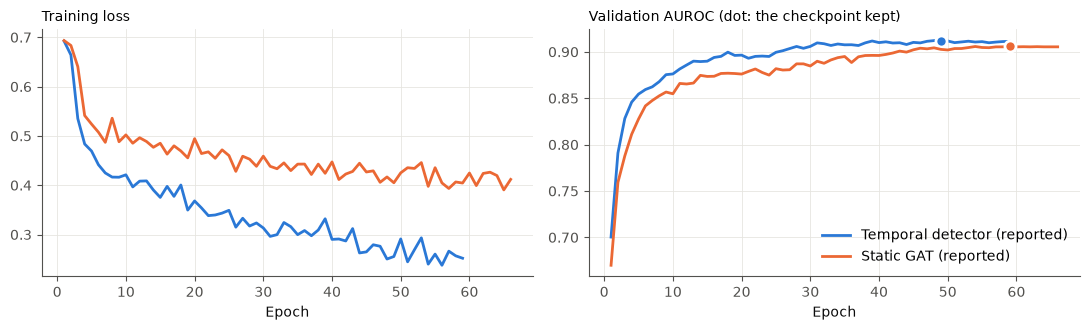

In [22]:
def run_dir(kind, seed=SEED):
    mine = RUNS / f"{kind}_s{seed}"
    if (mine / "phase2_best.pt").exists():
        return mine, "trained in this notebook"
    return REPORTED / f"{kind}_s{seed}", "reported"


fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for kind, colour, name in (("tgn", BLUE, "Temporal detector"), ("static_attn", ORANGE, "Static GAT")):
    d, source = run_dir(kind)
    h = json.load(open(d / "training_history.json"))
    ep = np.arange(1, len(h["train_loss"]) + 1)
    best = h["selection"]["best_epoch"]
    axes[0].plot(ep, h["train_loss"], color=colour, linewidth=2, label=f"{name} ({source})")
    axes[1].plot(ep, h["val_auroc"], color=colour, linewidth=2, label=f"{name} ({source})")
    axes[1].plot([best], [h["val_auroc"][best - 1]], "o", color=colour, markersize=8,
                 markeredgecolor="white", markeredgewidth=2)
axes[0].set_title("Training loss", loc="left", fontsize=10)
axes[1].set_title("Validation AUROC (dot: the checkpoint kept)", loc="left", fontsize=10)
for ax in axes:
    ax.set_xlabel("Epoch")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 6. Results

### 6.1 The models of seed `SEED`, scored by this notebook

The detector and the static GAT (and any other configuration trained above) are scored on the
validation (300 sequences) and test (500 sequences, 200 poisoned) partitions with the code of
section 4.4. A model trained here is set beside the reported model of the same seed and the
range of the five reported seeds. For a reported checkpoint, the score here should equal the
reported one (section 7.5).

In [23]:
ORDER = {split: sorted(splits[split]) for split in ("val", "test")}
Y = {split: labels_of(ORDER[split]) for split in ORDER}


def reported_seq_scores(kind, seed, split):
    z = np.load(REPORTED / f"{kind}_s{seed}" / f"window_scores_{split}_b1.npz", allow_pickle=True)
    return sequence_scores(z, ORDER[split])


SCORED, rows = {}, []
for kind in dict.fromkeys(["tgn", "static_attn", *TRAIN_MODELS]):
    d, source = run_dir(kind)
    model = load_model(kind, d / "phase2_best.pt") if source == "reported" else None
    for split in ("val", "test"):
        t0 = time.time()
        if source == "reported":
            res = score(model, TrajectoryDataset(splits[split], **inputs_for(kind)))
        else:
            res = dict(np.load(d / f"window_scores_{split}_b1.npz", allow_pickle=True))
        SCORED[(kind, split)] = res
        here_auc = roc_auc_score(Y[split], sequence_scores(res, ORDER[split]))
        rep = [roc_auc_score(Y[split], reported_seq_scores(kind, s, split)) for s in range(1, 6)]
        rows.append([kind, source, split, f"{here_auc:.4f}", f"{rep[SEED - 1]:.4f}",
                     f"{min(rep):.4f} to {max(rep):.4f}", f"{time.time() - t0:.0f} s"])
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

print(f"{'Model':<13}{'Checkpoint':<26}{'Split':<6}{'AUROC here':>11}{'Reported':>10}"
      f"{'Reported seeds 1-5':>22}{'Time':>8}")
for r in rows:
    print(f"{r[0]:<13}{r[1]:<26}{r[2]:<6}{r[3]:>11}{r[4]:>10}{r[5]:>22}{r[6]:>8}")

for split in ("val", "test"):
    d_ = sequence_scores(SCORED[("tgn", split)], ORDER[split])
    s_ = sequence_scores(SCORED[("static_attn", split)], ORDER[split])
    comb = (rankdata(d_) + rankdata(s_)) / (2 * len(d_))
    print(f"\nCombined detector (rank mean of the two), {split}: AUROC {roc_auc_score(Y[split], comb):.4f}")

Model        Checkpoint                Split  AUROC here  Reported    Reported seeds 1-5    Time
tgn          reported                  val        0.9121    0.9121      0.9106 to 0.9175    98 s
tgn          reported                  test       0.9110    0.9110      0.9033 to 0.9113   166 s
static_attn  reported                  val        0.9059    0.9059      0.8984 to 0.9243    53 s
static_attn  reported                  test       0.9086    0.9086      0.9056 to 0.9289    93 s

Combined detector (rank mean of the two), val: AUROC 0.9244

Combined detector (rank mean of the two), test: AUROC 0.9202


### 6.2 The headline: five seeds of each model

From the saved test scores of the 40 reported models. The combined detector averages, for each
seed pair, the ranks of the detector's and the static GAT's scores within the partition (the
configuration the pre-registered step 5 rule chose). Intervals: 2,000 bootstrap resamples of the
test sequences, the same resamples for every model. Compared, number by number, with
`experiments/seeds_coherence/ensemble_headline.json`.

In [24]:
def boots(y, n_boot=2000, seed=0):
    rng, out = np.random.default_rng(seed), []
    while len(out) < n_boot:
        i = rng.choice(len(y), len(y), replace=True)
        if 0 < y[i].sum() < len(i):
            out.append(i)
    return out


def group_stats(y, runs, B):
    au = [roc_auc_score(y, s) for s in runs]
    ap = [average_precision_score(y, s) for s in runs]
    dist = [np.mean([roc_auc_score(y[i], s[i]) for s in runs]) for i in B]
    return {"n_runs": len(runs), "auroc_per_run": au, "auroc_mean": float(np.mean(au)),
            "auroc_sd": float(np.std(au, ddof=1)) if len(au) > 1 else None,
            "ap_mean": float(np.mean(ap)),
            "auroc_ci95": [float(np.percentile(dist, 2.5)), float(np.percentile(dist, 97.5))]}


def group_diff(y, a_runs, b_runs, B):
    out = {}
    for m, fn in (("auroc", roc_auc_score), ("ap", average_precision_score)):
        point = np.mean([fn(y, s) for s in a_runs]) - np.mean([fn(y, s) for s in b_runs])
        dist = [np.mean([fn(y[i], s[i]) for s in a_runs]) - np.mean([fn(y[i], s[i]) for s in b_runs])
                for i in B]
        lo, hi = float(np.percentile(dist, 2.5)), float(np.percentile(dist, 97.5))
        out[m] = {"delta": float(point), "ci95": [lo, hi], "significant": bool(lo > 0 or hi < 0)}
    return out


t0 = time.time()
y, B = Y["test"], boots(Y["test"])
det = [reported_seq_scores("tgn", s, "test") for s in range(1, 6)]
sta = [reported_seq_scores("static_attn", s, "test") for s in range(1, 6)]
ens = [(rankdata(d_) + rankdata(t_)) / (2 * len(d_)) for d_, t_ in zip(det, sta)]
HEADLINE = {"detector_plus_static": group_stats(y, ens, B), "detector": group_stats(y, det, B),
            "static": group_stats(y, sta, B),
            "ensemble_minus_detector": group_diff(y, ens, det, B),
            "ensemble_minus_static": group_diff(y, ens, sta, B),
            "detector_minus_static": group_diff(y, det, sta, B)}

names = {"detector_plus_static": "Combined detector (detector + static GAT)",
         "detector": "Temporal detector", "static": "Static GAT"}
print(f"Test partition, 500 sequences, five seeds ({time.time() - t0:.0f} s)\n")
print(f"{'Model':<44}{'AUROC mean (SD)':>18}{'95% interval':>20}{'AP':>8}")
for k, label in names.items():
    g_ = HEADLINE[k]
    print(f"{label:<44}{g_['auroc_mean']:>9.4f} ({g_['auroc_sd']:.4f})"
          f"   [{g_['auroc_ci95'][0]:.4f}, {g_['auroc_ci95'][1]:.4f}]{g_['ap_mean']:>8.4f}")
print()
for k in ("ensemble_minus_detector", "ensemble_minus_static", "detector_minus_static"):
    d_ = HEADLINE[k]["auroc"]
    print(f"{k.replace('_', ' '):<28} {d_['delta']:+.4f}  [{d_['ci95'][0]:+.4f}, {d_['ci95'][1]:+.4f}]"
          + ("  significant" if d_["significant"] else "  interval includes zero"))

frozen = json.load(open(REPORTED / "ensemble_headline.json"))["test"]
same = all(HEADLINE[k] == {kk: frozen[k][kk] for kk in HEADLINE[k]} for k in HEADLINE)
print(f"\nEqual, number for number, to ensemble_headline.json: {same}")

Test partition, 500 sequences, five seeds (222 s)

Model                                          AUROC mean (SD)        95% interval      AP
Combined detector (detector + static GAT)      0.9221 (0.0089)   [0.8975, 0.9424]  0.9080
Temporal detector                              0.9088 (0.0032)   [0.8819, 0.9319]  0.8936
Static GAT                                     0.9156 (0.0120)   [0.8916, 0.9367]  0.8995

ensemble minus detector      +0.0133  [+0.0063, +0.0206]  significant
ensemble minus static        +0.0065  [+0.0001, +0.0134]  significant
detector minus static        -0.0068  [-0.0195, +0.0061]  interval includes zero

Equal, number for number, to ensemble_headline.json: True


### 6.3 ROC curves and score distributions, seed `SEED`, test partition

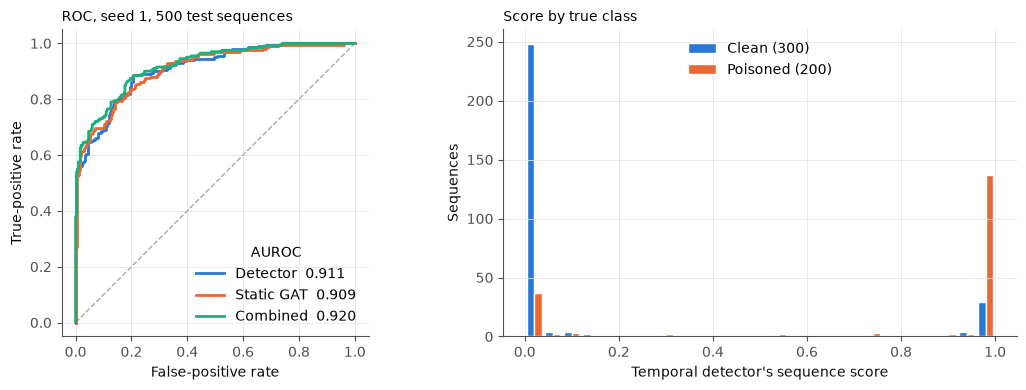

In [25]:
d_ = sequence_scores(SCORED[("tgn", "test")], ORDER["test"])
s_ = sequence_scores(SCORED[("static_attn", "test")], ORDER["test"])
curves = {"Detector": (d_, BLUE), "Static GAT": (s_, ORANGE),
          "Combined": ((rankdata(d_) + rankdata(s_)) / (2 * len(d_)), AQUA)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=GREY, linewidth=1, linestyle="--")
for name, (sc, colour) in curves.items():
    fpr, tpr, _ = roc_curve(Y["test"], sc)
    ax.plot(fpr, tpr, color=colour, linewidth=2, label=f"{name}  {roc_auc_score(Y['test'], sc):.3f}")
ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
ax.set_title(f"ROC, seed {SEED}, 500 test sequences", loc="left", fontsize=10)
ax.legend(frameon=False, loc="lower right", title="AUROC"); ax.set_aspect("equal")

ax = axes[1]
bins = np.linspace(0, 1, 26)
ax.hist([d_[Y["test"] == 0], d_[Y["test"] == 1]], bins=bins, color=[BLUE, ORANGE],
        label=["Clean (300)", "Poisoned (200)"], edgecolor="white", linewidth=1)
ax.set_xlabel("Temporal detector's sequence score"); ax.set_ylabel("Sequences")
ax.set_title("Score by true class", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper center")
plt.tight_layout(); plt.show()

The online scores, latency, record-level results, robustness sweeps and the figures of Chapter 4
come from the same saved models through the scripts that `03_reproduce_freeze2.ipynb` runs.

## 7. Check against the repository's code

The code above was written out from the repository (`src/`) for reading. This section imports
the repository's own modules and shows that the two agree:

1. every setting equals what the reported runs recorded;
2. the model inputs are the same tensors;
3. every model initialises to the same weights from the same seed, and the reported
   checkpoints load into the models here;
4. training gives the same losses and the same weights, step for step (on one CPU thread, the
   only setting in which the arithmetic is deterministic);
5. scoring gives the same scores.

In [26]:
CHECKS = []


def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  ({detail})" if detail else ""))


if RUN_CHECKS:
    import contextlib
    import functools
    import io
    import yaml
    from torch.utils.data import Subset
    sys.path.insert(0, str(ROOT))
    import src.data_generation.cached_dataset as repo_cache
    import src.data_generation.dataset as repo_dataset
    import src.experiments.score_windows as repo_score
    import src.experiments.train_variant as repo_variant
    import src.models.train as repo_train
    import src.models.tgn_detector as repo_tgn
    REPO_KIND = {"tgn_nocoherence": "tgn"}

### 7.1 Settings

In [27]:
if RUN_CHECKS:
    for kind in MODELS:
        for seed in range(1, 6):
            rc = json.load(open(REPORTED / f"{kind}_s{seed}" / "run_config.json"))
            a, c, inp = rc["args"], rc["config"], inputs_for(kind)
            mine = model_config(kind)
            ok = (a["model"] == REPO_KIND.get(kind, kind) and a["seed"] == seed
                  and a["arrival_window"] == inp["arrival_window"]
                  and a["temporal_window"] == inp["temporal_window"]
                  and bool(a.get("coherence_features", False)) == inp["coherence"]
                  and a["noise_augment_prob"] == NOISE["prob"] and a["noise_sigma_max"] == NOISE["sigma_max"]
                  and a["memory_slots"] == CONFIG["model"]["memory_slots"] and a["window_target"] == "presence"
                  and all(c["training"][k] == v for k, v in mine["training"].items())
                  and all(c["model"][k] == v for k, v in mine["model"].items() if k != "node_meta_dim")
                  and c["model"].get("coherence_dim", 0) == (COHERENCE_DIM if inp["coherence"] else 0)
                  and c["simulation"]["embedding_dim"] == EMB_DIM)
            if not ok:
                check(f"settings of {kind}_s{seed}", False)
    check("every setting equals the run_config.json of all 40 reported runs",
          all(ok for name, ok, _ in CHECKS if name.startswith("settings")))

PASS  every setting equals the run_config.json of all 40 reported runs


### 7.2 Model inputs

The dataset here against the repository's `CachedTrajectoryDataset`, tensor by tensor, for 20
sequences and the three input variants; and the cache rebuilt here from the raw snapshots against
the cache on disk.

In [28]:
if RUN_CHECKS:
    ids = splits["val"][:10] + splits["test"][:10]
    for kind in ("tgn", "nostruct", "tgn_nocoherence"):
        inp = inputs_for(kind)
        mine = TrajectoryDataset(ids, **inp)
        repo = repo_cache.CachedTrajectoryDataset(
            str(DATA), sequence_ids=ids, temporal_window=inp["temporal_window"],
            structural_features=inp["structural"], arrival_window=inp["arrival_window"],
            coherence_features=inp["coherence"])
        ok, n = mine.windows == repo.windows, 0
        for i in range(len(mine)):
            a, b = mine[i], repo[i]
            ok &= a["label"] == b["graph_label"]
            for ga, gb in zip(a["graphs"], b["graphs"]):
                for key in ("x", "edge_index", "edge_attr", "node_labels", "node_ids", "y"):
                    ta, tb = getattr(ga, key), getattr(gb, key)
                    ok &= ta.dtype == tb.dtype and torch.equal(ta, tb)
                n += 1
        check(f"inputs for {kind}: identical tensors", ok, f"{n} snapshots")

    ok = True
    for sid in ids[:5]:
        built = build_cache_sequence(DATA / sid)
        with np.load(CACHE / f"{sid}.npz") as zz:
            ok &= sorted(built) == sorted(zz.files) and all(
                built[k].dtype == zz[k].dtype and np.array_equal(built[k], zz[k]) for k in built)
    check("cache rebuilt here from the raw snapshots equals the cache on disk", ok, "5 sequences")

PASS  inputs for tgn: identical tensors  (400 snapshots)


PASS  inputs for nostruct: identical tensors  (400 snapshots)


PASS  inputs for tgn_nocoherence: identical tensors  (400 snapshots)


PASS  cache rebuilt here from the raw snapshots equals the cache on disk  (5 sequences)


### 7.3 Models: same weights from the same seed, and the reported checkpoints load

In [29]:
if RUN_CHECKS:
    for kind in MODELS:
        cfg_mine, cfg_repo = model_config(kind), model_config(kind)
        set_seed(1)
        mine = build_model(kind, cfg_mine)
        set_seed(1)
        repo = repo_variant.model_class(REPO_KIND.get(kind, kind))(cfg_repo)
        sa, sb = mine.state_dict(), repo.state_dict()
        same = sa.keys() == sb.keys() and all(torch.equal(sa[k], sb[k]) for k in sa)
        rec = json.load(open(REPORTED / f"{kind}_s1" / "variant.json"))["parameters"]
        try:
            for s in range(1, 6):
                mine.load_state_dict(torch.load(REPORTED / f"{kind}_s{s}" / "phase2_best.pt",
                                                map_location="cpu", weights_only=True), strict=True)
            loads = True
        except RuntimeError:
            loads = False
        check(f"{kind}: same initial weights as the repository's model", same,
              f"{n_params(mine):,} parameters, recorded {rec:,}; all 5 reported checkpoints load"
              if loads and n_params(mine) == rec else "size or checkpoint mismatch")

PASS  tgn: same initial weights as the repository's model  (680,515 parameters, recorded 680,515; all 5 reported checkpoints load)
PASS  static_attn: same initial weights as the repository's model  (312,003 parameters, recorded 312,003; all 5 reported checkpoints load)


PASS  no_memory: same initial weights as the repository's model  (411,075 parameters, recorded 411,075; all 5 reported checkpoints load)


PASS  no_aggregator: same initial weights as the repository's model  (581,443 parameters, recorded 581,443; all 5 reported checkpoints load)


PASS  static_wide: same initial weights as the repository's model  (680,943 parameters, recorded 680,943; all 5 reported checkpoints load)
PASS  meanpool: same initial weights as the repository's model  (672,194 parameters, recorded 672,194; all 5 reported checkpoints load)
PASS  nostruct: same initial weights as the repository's model  (676,931 parameters, recorded 676,931; all 5 reported checkpoints load)


PASS  tgn_nocoherence: same initial weights as the repository's model  (671,555 parameters, recorded 671,555; all 5 reported checkpoints load)


### 7.4 Training, step for step

For every configuration: one epoch on 12 training sequences (3 batches) and a validation pass on
8, once with the code here and once with the repository's `Trainer` (the class that trained the
reported models), from the same seed. The losses, the validation AUROCs and every weight
afterwards must be identical. Both run on one CPU thread: on a GPU or on several CPU threads the
order in which parallel sums are accumulated varies from run to run, so even the same code gives
weights that differ in the last bits (about 1e-8) from one run to the next.

In [30]:
def repo_one_epoch(kind, seed, n_train, n_val):
    inp = inputs_for(kind)
    cfg = yaml.safe_load(open(ROOT / "configs" / "default.yaml"))        # as train_variant.py does
    cfg["training"]["epochs_supervised"] = 1
    cfg["model"]["memory_slots"] = "per_window"
    cfg["model"]["readout"] = "attention"
    cfg["training"]["window_target"] = "presence"
    cfg["model"]["edge_dim"] = 2
    cfg["training"]["temporal_window"] = inp["temporal_window"]
    if inp["coherence"]:
        cfg["model"]["coherence_dim"] = repo_dataset.COHERENCE_DIM
    ds_cls = functools.partial(repo_cache.CachedTrajectoryDataset, arrival_window=ARRIVAL_WINDOW,
                               coherence_features=inp["coherence"])
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        repo_train.set_seed(seed)
        t = repo_train.Trainer(cfg, str(DATA), torch.device("cpu"), noise_augment_prob=NOISE["prob"],
                               noise_sigma_max=NOISE["sigma_max"],
                               model_cls=repo_variant.model_class(REPO_KIND.get(kind, kind)),
                               structural_features=inp["structural"], select_by="auroc",
                               dataset_cls=ds_cls)
        bs = cfg["training"]["batch_size"]
        t.train_loader = DataLoader(Subset(t.train_dataset, range(n_train)), batch_size=bs,
                                    shuffle=True, collate_fn=repo_dataset.collate_trajectories)
        t.val_loader = DataLoader(Subset(t.val_dataset, range(n_val)), batch_size=bs,
                                  shuffle=False, collate_fn=repo_dataset.collate_trajectories)
        a, b = cfg["training"]["loss_alpha"], cfg["training"]["loss_beta"]
        loss = t._train_epoch(a, b, 0, 1)
        v_loss, v_auroc, v_node = t._evaluate(t.val_loader, a, b)
    return (loss, v_loss, v_auroc, v_node), t.model.state_dict()


if RUN_CHECKS:
    cpu = torch.device("cpu")
    threads = torch.get_num_threads()
    torch.set_num_threads(1)
    try:
        for kind in MODELS:
            t0 = time.time()
            model, h = train(kind, SEED, RUNS / "check" / kind, splits["train"][:12],
                             splits["val"][:8], epochs=1, device=cpu, verbose=False)
            mine_numbers = (h["train_loss"][0], h["val_loss"][0], h["val_auroc"][0],
                            h["val_node_auroc"][0])
            repo_numbers, repo_state = repo_one_epoch(kind, SEED, 12, 8)
            sa = model.state_dict()
            n_same = sum(k in repo_state and torch.equal(sa[k], repo_state[k]) for k in sa)
            same_numbers = mine_numbers == repo_numbers
            check(f"{kind}: one training epoch identical to the repository's Trainer",
                  same_numbers and sa.keys() == repo_state.keys() and n_same == len(sa),
                  f"train loss {mine_numbers[0]:.6f}; losses and AUROCs "
                  f"{'identical' if same_numbers else 'DIFFERENT'}; {n_same} of {len(sa)} weight "
                  f"tensors identical; {time.time() - t0:.0f} s")
    finally:
        torch.set_num_threads(threads)

PASS  tgn: one training epoch identical to the repository's Trainer  (train loss 0.708067; losses and AUROCs identical; 34 of 34 weight tensors identical; 21 s)


PASS  static_attn: one training epoch identical to the repository's Trainer  (train loss 0.699484; losses and AUROCs identical; 26 of 26 weight tensors identical; 7 s)


PASS  no_memory: one training epoch identical to the repository's Trainer  (train loss 0.704904; losses and AUROCs identical; 30 of 30 weight tensors identical; 16 s)


PASS  no_aggregator: one training epoch identical to the repository's Trainer  (train loss 0.726276; losses and AUROCs identical; 30 of 30 weight tensors identical; 7 s)


PASS  static_wide: one training epoch identical to the repository's Trainer  (train loss 0.725645; losses and AUROCs identical; 26 of 26 weight tensors identical; 10 s)


PASS  meanpool: one training epoch identical to the repository's Trainer  (train loss 0.708069; losses and AUROCs identical; 30 of 30 weight tensors identical; 18 s)


PASS  nostruct: one training epoch identical to the repository's Trainer  (train loss 0.733366; losses and AUROCs identical; 34 of 34 weight tensors identical; 18 s)


PASS  tgn_nocoherence: one training epoch identical to the repository's Trainer  (train loss 0.702518; losses and AUROCs identical; 34 of 34 weight tensors identical; 16 s)


### 7.5 Scoring

First, exactly, on one CPU thread: the reported seed 1 checkpoints of the detector and the static GAT
scored on 10 test sequences by the code here and by the repository's `score_split`. Then the
scores of section 6.1 (on the GPU) against the scores saved when the reported models were
evaluated.

In [31]:
if RUN_CHECKS:
    ids = splits["test"][:10]
    threads = torch.get_num_threads()
    torch.set_num_threads(1)
    for kind in ("tgn", "static_attn"):
        ckpt = REPORTED / f"{kind}_s1" / "phase2_best.pt"
        mine = score(load_model(kind, ckpt, cpu), TrajectoryDataset(ids, **inputs_for(kind)), cpu)
        inp = inputs_for(kind)
        repo_model = repo_score.build_model(kind, model_config(kind))
        repo_model.load_state_dict(torch.load(ckpt, map_location="cpu", weights_only=True))
        repo_ds = repo_cache.CachedTrajectoryDataset(
            str(DATA), sequence_ids=ids, temporal_window=inp["temporal_window"],
            structural_features=True, arrival_window=ARRIVAL_WINDOW, coherence_features=True)
        repo_res, _, _ = repo_score.score_split(repo_model, repo_ds, cpu, 1, inp["temporal_window"],
                                                node_scores=True, log_every=0)
        same = all(np.array_equal(mine[k], repo_res[k]) for k in ("y", "score", "node_score", "node_label"))
        check(f"{kind}: scores identical to the repository's score_split on the CPU", same,
              "10 sequences, sequence and record scores")
    torch.set_num_threads(threads)

    for (kind, split), res in SCORED.items():
        if run_dir(kind)[1] != "reported":
            continue
        z = np.load(REPORTED / f"{kind}_s{SEED}" / f"window_scores_{split}_b1.npz", allow_pickle=True)
        same_order = np.array_equal(z["seq"], res["seq"])
        diff = np.abs(z["score"] - res["score"]).max()
        a1 = roc_auc_score(z["y"], z["score"]); a2 = roc_auc_score(res["y"], res["score"])
        check(f"{kind}_s{SEED} {split}: scores here equal the saved scores (GPU)",
              same_order and diff < 1e-5 and round(a1, 4) == round(a2, 4),
              f"largest difference {diff:.1e}; AUROC {a2:.4f} here, {a1:.4f} saved")

PASS  tgn: scores identical to the repository's score_split on the CPU  (10 sequences, sequence and record scores)


PASS  static_attn: scores identical to the repository's score_split on the CPU  (10 sequences, sequence and record scores)
PASS  tgn_s1 val: scores here equal the saved scores (GPU)  (largest difference 2.4e-07; AUROC 0.9121 here, 0.9121 saved)
PASS  tgn_s1 test: scores here equal the saved scores (GPU)  (largest difference 2.4e-07; AUROC 0.9110 here, 0.9110 saved)
PASS  static_attn_s1 val: scores here equal the saved scores (GPU)  (largest difference 1.2e-07; AUROC 0.9059 here, 0.9059 saved)
PASS  static_attn_s1 test: scores here equal the saved scores (GPU)  (largest difference 1.2e-07; AUROC 0.9086 here, 0.9086 saved)


In [32]:
if RUN_CHECKS:
    passed = sum(ok for _, ok, _ in CHECKS)
    print(f"{passed} of {len(CHECKS)} checks passed")

27 of 27 checks passed
